<a href="https://colab.research.google.com/github/Nasim-Amani/tag-recommender-agent-learning/blob/main/Phase4_Tag_Graphs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 4 — Tag Graphs: using the relations *between* tags
**Tag Recommender Agent roadmap · Weeks 6–8**

### 🎯 The idea in one sentence
Tags are **not independent**: some almost always appear together, some never do. If we know a product is `Material=human hair`, it very likely also has a `Hair Type` (straight, wavy or curly) — and it certainly has no `Skin Type`.

This is the **"neighbouring tag attributes"** part of our proposal.

**Forecasting analogy — correlated variables:** in multivariate forecasting, knowing the wind speed tells you a lot about the gust, even before looking at the gust's own history. Here: knowing one confident tag tells you a lot about the others.

### Why this phase, after Phase 3?
Phase 3 ended with a clear diagnosis:
- Four very different text methods (TF-IDF + LR, DistilBERT, kNN, Hybrid) all hit a **ceiling at P@3 ≈ 0.46**.
- Neighbours found **by text** mostly repeat what the text already says.

→ The next gain must come from **knowledge that is not in the product's text**. The tag graph is the first such source: it is learned from **how tags co-occur** across all training products.

### What you will do
| Section | What | Roadmap task |
|---|---|---|
| 1 | Load data, rebuild the Phase 2/3 scores | — |
| 2 | Graph basics in 5 minutes | 📘 Graph basics |
| 3 | Count which tags appear together | 🔨 Build tag co-occurrence graph |
| 4 | **PMI**: "together more than by chance?" | 📘 PMI |
| 5 | Build & explore the graph (clusters, conflicts) | 🔨 networkx graph |
| 6 | **Graph re-ranking**: confident tags boost their partners | 🎯 Graph re-ranking / tag completion |
| 7 | **Ablation**: with vs without the graph | 📊 Ablation |
| 8 | Tag embeddings with random walks (node2vec idea) | 📘 node2vec |
| 9 | GCN: the deep-learning version (concept) | 📘 optional GCN |
| 10 Scoreboard · 11 Save · 12 Summary | | |

### The bar to beat (test set)
**TF-IDF + LR: P@3 0.463 · micro-F1 0.579 · macro-F1 0.306 · MAP 0.683** (Hybrid: P@3 0.465)

## 0 · Setup

In [1]:
!pip -q install -U networkx gensim

In [2]:
import json, re, os, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

pd.set_option("display.max_colwidth", 100)
np.random.seed(42)
BLUE, GRAY, ORANGE, GREEN, INK = "#2a6fdb", "#9aa0a6", "#e8710a", "#1e8e3e", "#222222"

## 1 · Load the data and rebuild the baseline scores
**Why:** the tag graph doesn't predict tags on its own — it **improves the scores of another model**. So we need the Phase 2/3 models' scores on **validation** (to tune) and **test** (to report).

- From **Phase 2:** products, tags, Y, vendor split
- From **Phase 3:** neighbours and best settings → rebuild the kNN and Hybrid scores
- **Rebuild TF-IDF + LR** (~1 min), because Phase 2 only saved test scores

In [3]:
from google.colab import drive
drive.mount("/content/drive")
DIR = "/content/drive/MyDrive/tag_agent"

Mounted at /content/drive


In [4]:
CATEGORY = "All_Beauty"
P2, P3, OUT = f"{DIR}/phase2", f"{DIR}/phase3", f"{DIR}/phase4"
os.makedirs(OUT, exist_ok=True)

data = pd.read_pickle(f"{P2}/{CATEGORY}_phase2.pkl")
Y    = np.load(f"{P2}/Y.npy")
TAGS = np.array(json.load(open(f"{P2}/tags.json")))
ph3  = json.load(open(f"{P3}/results.json"))

m_tr, m_va, m_te = [(data["split"] == s).values for s in ("train", "val", "test")]
Y_tr, Y_va, Y_te = Y[m_tr], Y[m_va], Y[m_te]
TAG_ATTR = np.array([t.split("=")[0] for t in TAGS])
TAG_VAL  = np.array([t.split("=", 1)[1] for t in TAGS])
texts = data["clean"].values
te_df = data[m_te].reset_index(drop=True)
print(f"Products: {len(data):,} | tags: {len(TAGS)} | train {m_tr.sum():,} · val {m_va.sum():,} · test {m_te.sum():,}")

Products: 19,401 | tags: 211 | train 13,702 · val 2,716 · test 2,983


### Same metric functions as Phases 2 and 3

In [5]:
from sklearn.metrics import f1_score, average_precision_score, ndcg_score

def at_k(Yt, S, k):
    topk = np.argsort(-S, axis=1)[:, :k]
    hits = np.take_along_axis(Yt, topk, axis=1).sum(1)
    return float((hits / k).mean()), float((hits / Yt.sum(1)).mean())

def binarize(S, thr, at_least_one=True):
    P = (S >= thr).astype(int)
    if at_least_one:
        empty = P.sum(1) == 0
        P[empty, S[empty].argmax(1)] = 1
    return P

def evaluate(Yt, S, thr=0.5):
    P = binarize(S, thr)
    present = np.flatnonzero(Yt.sum(0) > 0)
    p3, r3 = at_k(Yt, S, 3); p5, r5 = at_k(Yt, S, 5)
    return {"micro-F1": f1_score(Yt, P, average="micro", zero_division=0),
            "macro-F1": f1_score(Yt, P, average="macro", labels=present, zero_division=0),
            "P@3": p3, "R@3": r3, "P@5": p5, "R@5": r5,
            "MAP": average_precision_score(Yt, S, average="samples"),
            "NDCG@5": ndcg_score(Yt, S, k=5)}

def tune_threshold(Yv, Sv):
    grid = np.round(np.arange(0.05, 0.95, 0.05), 2)
    f1s = [f1_score(Yv, binarize(Sv, g), average="micro", zero_division=0) for g in grid]
    return float(grid[int(np.argmax(f1s))])

results = {k: v for k, v in ph3["results_test"].items()}     # scoreboard so far (Phases 2 + 3)
pd.DataFrame(results).T[["micro-F1", "macro-F1", "P@3", "MAP"]].round(3)

,micro-F1,macro-F1,P@3,MAP
Popularity,0.152,0.007,0.134,0.198
TF-IDF + LR,0.579,0.306,0.463,0.683
DistilBERT,0.589,0.318,0.463,0.686
kNN (embeddings),0.526,0.266,0.418,0.613
kNN (TF-IDF),0.541,0.269,0.430,0.634
Hybrid (LR + kNN),0.580,0.304,0.465,0.687


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

t0 = time.time()
tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_df=0.5,
                        max_features=100_000, sublinear_tf=True)
X_tr = tfidf.fit_transform(texts[m_tr])
lr = OneVsRestClassifier(LogisticRegression(C=4.0, solver="liblinear", max_iter=1000), n_jobs=-1).fit(X_tr, Y_tr)
S_va_lr = lr.predict_proba(tfidf.transform(texts[m_va]))
S_te_lr = lr.predict_proba(tfidf.transform(texts[m_te]))

# Phase 3 hybrid, rebuilt from the saved neighbours and settings
def knn_scores(sims, idxs, k, power, Y_index):
    w = np.clip(sims[:, :k], 0, None) ** power
    return (w[:, :, None] * Y_index[idxs[:, :k]]).sum(1) / (w.sum(1, keepdims=True) + 1e-9)
b = ph3["best"]
nv, nt = np.load(f"{P3}/neighbours_val.npz"), np.load(f"{P3}/neighbours_test.npz")
Ytr32 = Y_tr.astype("float32")
S_va_knn = knn_scores(nv["sim"], nv["idx"], b["knn_emb"]["k"], b["knn_emb"]["power"], Ytr32)
S_te_knn = knn_scores(nt["sim"], nt["idx"], b["knn_emb"]["k"], b["knn_emb"]["power"], Ytr32)
A = b["hybrid"]["alpha"]
S_va_hyb, S_te_hyb = A * S_va_lr + (1 - A) * S_va_knn, A * S_te_lr + (1 - A) * S_te_knn
print(f"Rebuilt TF-IDF + LR and Hybrid (α = {A}) in {time.time() - t0:.0f}s")
print("Check vs Phase 3 → LR P@3:", round(at_k(Y_te, S_te_lr, 3)[0], 3), "| Hybrid P@3:", round(at_k(Y_te, S_te_hyb, 3)[0], 3))

Rebuilt TF-IDF + LR and Hybrid (α = 0.9) in 81s
Check vs Phase 3 → LR P@3: 0.463 | Hybrid P@3: 0.465


**Check:** the two P@3 values should match the Phase 3 scoreboard (≈ 0.463 and 0.465). If they do, everything below is comparable.

## 2 · Graph basics in 5 minutes 📘
A **graph** is just *things* and *connections between them*.

| Word | Meaning | In our tag graph |
|---|---|---|
| **node** | a thing | one **tag**, e.g. `Material=human hair` |
| **edge** | a connection between two nodes | the two tags **appear together** on products |
| **weight** | how strong the connection is | **how much more** than by chance they co-occur (PMI, Section 4) |
| **neighbours** of a node | nodes it is connected to | tags that tend to come with it |
| **degree** | number of neighbours | how "social" a tag is |
| **community** | a group of nodes connected mostly to each other | e.g. all **hair-extension** tags |

**Tiny example** (3 products):
- P1: human hair, straight · P2: human hair, wavy · P3: cream, dry

→ edges: *human hair — straight*, *human hair — wavy*, *cream — dry*. Two separate groups: a **hair** group and a **skin-care** group. No edge between "human hair" and "dry" → they never appeared together.

*Forecasting analogy:* like a **correlation network** between weather stations: nodes = stations, edges = strongly correlated pairs.

In [7]:
G_demo = nx.Graph()
G_demo.add_edges_from([("human hair", "straight"), ("human hair", "wavy"), ("cream", "dry")])
print("nodes:", list(G_demo.nodes))
print("neighbours of 'human hair':", list(G_demo.neighbors("human hair")))
print("degree:", dict(G_demo.degree()))
print("groups (connected components):", [sorted(c) for c in nx.connected_components(G_demo)])

nodes: ['human hair', 'straight', 'wavy', 'cream', 'dry']
neighbours of 'human hair': ['straight', 'wavy']
degree: {'human hair': 2, 'straight': 1, 'wavy': 1, 'cream': 1, 'dry': 1}
groups (connected components): [['human hair', 'straight', 'wavy'], ['cream', 'dry']]


## 3 · Count which tags appear together 🔨
**Goal:** a table that says, for every pair of tags, **on how many training products both appear**.

**The trick:** with the 0/1 matrix Y (products × tags), one matrix product gives all pair counts at once:

**C = Yᵀ · Y** → a tags × tags table where
- **C[a, b]** = number of products that have **both** tag a and tag b
- **C[a, a]** (the diagonal) = number of products with tag a

*Mini example:* if 3 products have `human hair` and 2 of them also have `straight`, then C[human hair, straight] = 2.

⚠️ **Train products only** — counting pairs from test products would leak test labels into the graph.

In [8]:
n_tr = len(Y_tr)
Cmat = (Y_tr.T @ Y_tr).astype(np.int64)          # tags × tags co-occurrence counts
count = np.diag(Cmat).copy()                     # products per tag

iu = np.triu_indices(len(TAGS), k=1)             # each pair once (upper triangle)
pairs = pd.DataFrame({"tag A": TAGS[iu[0]], "tag B": TAGS[iu[1]], "together": Cmat[iu]})
pairs = pairs[pairs["together"] > 0].sort_values("together", ascending=False)
print(f"Co-occurrence matrix: {Cmat.shape} | pairs that ever appear together: {len(pairs):,} of {len(iu[0]):,}")
pairs.head(10)

Co-occurrence matrix: (211, 211) | pairs that ever appear together: 4,356 of 22,155


,tag A,tag B,together
8856,Hair Type=straight,Material=human hair,653
15618,Material Feature=natural,Material=human hair,589
9339,Hair Type=wavy,Material=human hair,513
8837,Hair Type=straight,Material Feature=natural,459
7543,Hair Type=curly,Material=synthetic,365
9320,Hair Type=wavy,Material Feature=natural,343
7459,Hair Type=curly,Hair Type=wavy,301
9358,Hair Type=wavy,Material=synthetic,296
7524,Hair Type=curly,Material=human hair,291
8875,Hair Type=straight,Material=synthetic,287


**How to read it:** the most frequent pairs. Notice a problem: very common tags (e.g. `human hair`, `natural`) appear in many pairs **just because they are common** — not necessarily because they *belong* together. Section 4 fixes this.

## 4 · PMI: "together more often than by chance?" 📘
**The problem with raw counts:** if 30% of products have tag A and 30% have tag B, then even if A and B are **unrelated**, about 30% × 30% = **9%** of products will have both — just by chance.

**PMI (Pointwise Mutual Information)** compares what we **see** with what **chance** would give:

**PMI(a, b) = log [ P(a and b) / ( P(a) · P(b) ) ]**

| PMI | Meaning | Example |
|---|---|---|
| **> 0** | together **more** than chance → they **belong together** | `human hair` & `wavy` |
| **≈ 0** | independent | |
| **< 0** | together **less** than chance → they **avoid** each other | `human hair` & `Skin Type=dry` |

**Worked example** (1,000 products): `human hair` on 200, `wavy` on 100, both on 60.
- Chance would give 0.2 × 0.1 × 1,000 = **20** products with both; we see **60** → 3× more
- PMI = log(0.06 / (0.2 × 0.1)) = log 3 = **1.10** → strong positive link

**Two helpful variants:**
- **NPMI** (normalized PMI): squeezes PMI into **−1 … +1** (+1 = always together, −1 = never) → easier to compare pairs
- **P(b | a)** = "of the products with tag a, what share also has b?" = C[a, b] / C[a, a] → **directional** and easy to read: P(wavy | human hair) = 60/200 = **0.30**

*Analogy:* this is **lift** in market-basket analysis ("people who buy bread buy butter 3× more often than average").

In [9]:
MIN_CO = 5                                         # ignore pairs seen together < 5 times (too noisy)

P_a  = count / n_tr                                # P(a)
P_ab = Cmat / n_tr                                 # P(a and b)
with np.errstate(divide="ignore", invalid="ignore"):
    PMI  = np.log(P_ab / np.outer(P_a, P_a))
    NPMI = PMI / -np.log(P_ab)
    COND = Cmat / count[:, None]                   # COND[a, b] = P(b | a)
reliable = (Cmat >= MIN_CO)
np.fill_diagonal(reliable, False)
for M in (PMI, NPMI, COND):
    M[~np.isfinite(M)] = 0.0

# check the worked example: 1,000 products, a on 200, b on 100, both on 60
print("Worked example PMI:", round(np.log((60 / 1000) / ((200 / 1000) * (100 / 1000))), 2), "| P(b|a):", 60 / 200)

idx = {t: i for i, t in enumerate(TAGS)}
pairs["NPMI"] = [NPMI[idx[a], idx[b]] for a, b in zip(pairs["tag A"], pairs["tag B"])]
pairs["P(B|A)"] = [COND[idx[a], idx[b]] for a, b in zip(pairs["tag A"], pairs["tag B"])]
strong = pairs[pairs["together"] >= MIN_CO].sort_values("NPMI", ascending=False)
strong.head(12).round(3)

Worked example PMI: 1.1 | P(b|a): 0.3


,tag A,tag B,together,NPMI,P(B|A)
19534,Product Benefits=clean,Product Benefits=massage,17,0.846,0.586
20671,Recommended Uses For Product=for blush,Recommended Uses For Product=for foundation,21,0.813,0.778
22055,Special Feature=matte,Special Feature=travel size,63,0.807,0.863
19744,Product Benefits=exfoliating,Product Benefits=massage,22,0.768,0.286
13010,Item Form=pair,Material=faux mink,138,0.746,0.377
4198,Coverage=full well tips,Style=french,103,0.743,0.609
21806,Skin Type=combination,Skin Type=normal,35,0.740,0.515
15152,Material Feature=cruelty free,Material=faux mink,126,0.714,0.346
20724,Recommended Uses For Product=for eyeshadow,Recommended Uses For Product=for foundation,16,0.701,0.457
12991,Item Form=pair,Material Feature=cruelty free,192,0.699,0.525


**How to read it:** the pairs that belong together **most strongly** (not just the most frequent). High **NPMI** = rarely apart. **P(B|A)** = how often B follows when A is present.

### Pairs that avoid each other
Pairs with **many expected** co-occurrences but **few or none observed** → candidate **conflicts** ("these two tags should not be on the same product").

In [10]:
expected = np.outer(count, count) / n_tr
conflict = pd.DataFrame({"tag A": TAGS[iu[0]], "tag B": TAGS[iu[1]],
                         "expected by chance": expected[iu], "observed": Cmat[iu]})
conflict = conflict[(conflict["expected by chance"] >= 10) & (conflict["observed"] <= 1)]
conflict = conflict[[TAG_ATTR[idx[a]] != TAG_ATTR[idx[b]] for a, b in zip(conflict["tag A"], conflict["tag B"])]]
print(f"{len(conflict):,} pairs of different attributes expected ≥ 10 times but seen ≤ 1 time")
conflict.sort_values("expected by chance", ascending=False).head(10).round(1)

270 pairs of different attributes expected ≥ 10 times but seen ≤ 1 time


,tag A,tag B,expected by chance,observed
11619,Item Form=cream,Material=human hair,105.6,0
12468,Item Form=liquid,Material=human hair,94.7,0
12189,Item Form=gel,Material=human hair,84.6,0
11638,Item Form=cream,Material=synthetic,70.2,0
15625,Material Feature=natural,Material=plastic,65.1,1
12208,Item Form=gel,Material=synthetic,56.3,0
17668,Material=human hair,Skin Type=sensitive,50.3,0
8930,Hair Type=straight,Skin Type=sensitive,47.3,0
17664,Material=human hair,Skin Type=dry,46.9,0
14184,Item Form=spray,Material=human hair,46.9,0


**How to read it:** each row = two tags that **chance alone** would put together ≥ 10 times, but that (almost) **never** co-occur → e.g. a `Hair Type` with a `Skin Type`. These are the "impossible combinations" a verifier can reject (remember the "Conditioning" lip balm tagged `Hair Type=dry` in Phase 2).

## 5 · Build and explore the tag graph 🔨
**Goal:** the NPMI table (211 × 211 numbers) is impossible to read, so we turn it into a **map**:
- each **tag** → a dot (**node**)
- two tags that **belong together** → a line between them (**edge**)

Then we ask: ***"which groups of tags are mostly connected to each other?"*** → **communities**.

**Analogy: a social network.** People = dots, friendships = lines. Without knowing anything about the people, you can still find **friend groups**, because they're mostly connected among themselves. Here the "people" are tags, and the friend groups turn out to be **product families**.

**The code in 3 parts:**
1. **Make the map:** one node per tag; an edge if the two tags were seen together **≥ 5 times** and **NPMI > 0**; edge weight = NPMI (stronger belonging → stronger line).
2. **Lonely tags:** `isolated` = tags with no edge at all (never reliably appear with another tag).
3. **Find the groups:** `greedy_modularity_communities` splits the map into groups with **many lines inside, few between**; we print each group's 8 most common tags (values only).

In [11]:
G = nx.Graph()
G.add_nodes_from((str(t), {"attr": str(TAG_ATTR[i]), "count": int(count[i])}) for i, t in enumerate(TAGS))
for a, b in zip(*np.where(np.triu(reliable & (NPMI > 0), 1))):
    G.add_edge(str(TAGS[a]), str(TAGS[b]), weight=float(NPMI[a, b]), together=int(Cmat[a, b]))

isolated = [n for n in G.nodes if G.degree(n) == 0]
print(f"Graph: {G.number_of_nodes()} tags, {G.number_of_edges():,} edges | isolated tags (no reliable partner): {len(isolated)}")

comms = sorted(nx.algorithms.community.greedy_modularity_communities(G, weight="weight"), key=len, reverse=True)
comms = [c for c in comms if len(c) > 1]
for k, c in enumerate(comms[:6]):
    top = sorted(c, key=lambda t: -G.nodes[t]["count"])[:8]
    print(f"\nCommunity {k + 1} ({len(c)} tags): " + " · ".join(t.split('=', 1)[1] for t in top))

Graph: 211 tags, 1,038 edges | isolated tags (no reliable partner): 8

Community 1 (46 tags): liquid · powder · matte · glossy · shimmery · light · stick · pencil

Community 2 (45 tags): cream · sensitive · dry · spray · oil · bar · lotion · unscented

Community 3 (32 tags): gel · plastic · acrylic · metal · french · full well tips · pink · white

Community 4 (30 tags): human hair · natural · straight · curly · wavy · synthetic · sew-in · weave

Community 5 (20 tags): black · pair · cruelty free · cotton · faux mink · silk · wrap · vegan

Community 6 (15 tags): dry · thick · damaged · ceramic · thin · color treated · fine · frizzy


### 📊 Result: the graph found 6 product families by itself
**211 tags, 1,038 edges, 8 isolated tags.**

| Group | Example tags | Product family |
|---|---|---|
| 1 (46 tags) | liquid · powder · matte · glossy · shimmery · stick · pencil | 💄 makeup |
| 2 (45 tags) | cream · sensitive · dry · lotion · bar · unscented | 🧴 skin & body care |
| 3 (32 tags) | gel · acrylic · french · full well tips · pink | 💅 nails |
| 4 (30 tags) | human hair · straight · curly · wavy · sew-in · weave | 💇 hair extensions & wigs |
| 5 (20 tags) | pair · faux mink · silk · cotton · wrap | 👁️ lashes & hair accessories |
| 6 (15 tags) | dry · damaged · color treated · frizzy · thin | 🧖 hair care |

- **The graph never read a product title**: it found the shop's product families **from tag co-occurrence alone**.
- **"dry" in groups 2 and 6** = two different tags: `Skin Type=dry` vs `Hair Type=dry` (only values are printed).
- **For the agent:** if a product is confidently in the **nails** family, tags from the **hair-extension** family are very unlikely → a **"does this combination make sense?"** check.

### 🔍 One tag's partners: `show_ego`
**Goal:** zoom in on **one tag** and list the tags that typically come with it.
- **P(partner | tag):** of the products with this tag, what share also has the partner → *how common*
- **NPMI:** how strongly they belong together beyond chance → *how exclusive*
- **together:** raw count

In [12]:
def show_ego(tag, n=10):
    # the strongest partners of one tag
    i = idx[tag]
    nb = [(TAGS[j], COND[i, j], NPMI[i, j], Cmat[i, j]) for j in np.flatnonzero(reliable[i] & (NPMI[i] > 0))]
    out = pd.DataFrame(nb, columns=["partner tag", f"P(partner | {tag.split('=', 1)[1]})", "NPMI", "together"])
    return out.sort_values(out.columns[1], ascending=False).head(n).round(3)

top_tag = str(TAGS[np.argmax(count)])
print("Most common tag:", top_tag)
show_ego(top_tag)

Most common tag: Material=human hair


,partner tag,P(partner | human hair),NPMI,together
7,Hair Type=straight,0.432,0.469,653
17,Material Feature=natural,0.390,0.402,589
9,Hair Type=wavy,0.339,0.421,513
5,Hair Type=curly,0.192,0.190,291
16,Installation Type=weave,0.112,0.451,169
0,Color=black,0.095,0.222,143
18,Special Feature=glueless,0.061,0.287,92
13,Installation Type=sew-in,0.050,0.204,76
6,Hair Type=kinky,0.040,0.327,60
11,Installation Type=clip-in,0.036,0.257,55


### 📊 Result: partners of `Material=human hair`
- **Hair Type almost always present:** straight 43% · wavy 34% · curly 19% · kinky 4% ≈ **100%** → completion rule: *human hair ⇒ suggest a Hair Type*.
- **P vs NPMI:** `weave` has P only **0.11** but NPMI **0.45** → most human-hair products aren't weaves, but **a weave is almost always human hair** (rare but tight link).
- All partners are plausible (natural, glueless, sew-in, clip-in) → the graph captures real product logic.

**Try other tags:** `show_ego("Item Form=cream")`, `show_ego("Finish Type=matte")` → the tags that typically come **with** them, and how often.

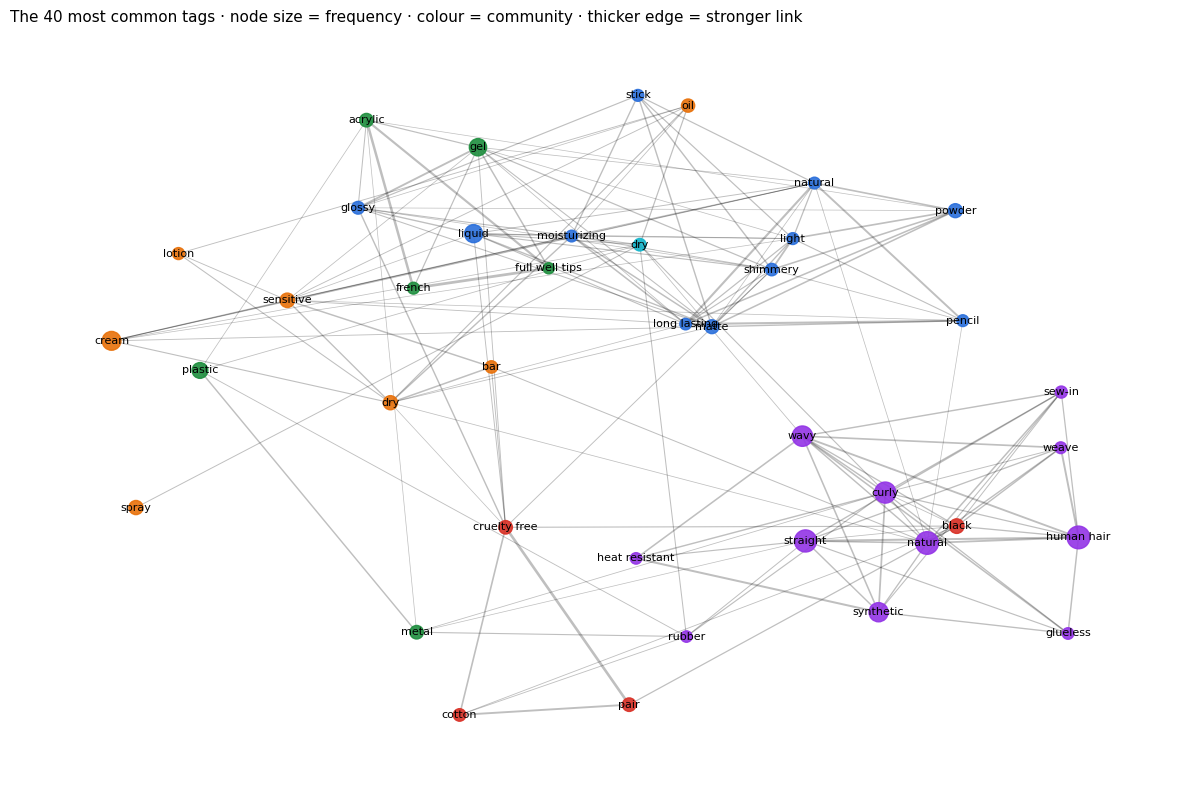

In [13]:
# picture: the 40 most common tags, coloured by community
top40 = [str(TAGS[i]) for i in np.argsort(-count)[:40]]
H = G.subgraph(top40).copy()
comm_of = {t: k for k, c in enumerate(comms) for t in c}
palette = [BLUE, ORANGE, GREEN, "#9334e6", "#d93025", "#12b5cb", GRAY]
colors = [palette[min(comm_of.get(t, 6), 6)] for t in H.nodes]
sizes = [40 + 0.15 * H.nodes[t]["count"] for t in H.nodes]
pos = nx.spring_layout(H, weight="weight", seed=7, k=0.6)

fig, ax = plt.subplots(figsize=(12, 8))
nx.draw_networkx_edges(H, pos, ax=ax, alpha=0.25, width=[0.5 + 2 * H[u][v]["weight"] for u, v in H.edges])
nx.draw_networkx_nodes(H, pos, ax=ax, node_color=colors, node_size=sizes, alpha=0.9)
nx.draw_networkx_labels(H, pos, ax=ax, labels={t: t.split("=", 1)[1] for t in H.nodes}, font_size=8)
ax.set_title("The 40 most common tags · node size = frequency · colour = community · thicker edge = stronger link",
             loc="left", fontsize=11)
ax.axis("off"); plt.tight_layout(); plt.show()

## 6 · Graph re-ranking: confident tags boost their partners 🎯
**Goal:** use the graph to **fix a model's scores**: add likely tags the text doesn't mention, and push down tags that don't fit. This is the **tag completion** idea of the proposal.

### The situation
A hair bundle: *"Brazilian Body Wave Bundles 3 pcs"*. The LR model (Baseline 1) gives these scores:

| tag | LR score |
|---|---|
| human hair | **0.90** ← very confident |
| cream | 0.25 |
| wavy | 0.22 |
| natural | 0.20 |

**Problem:** `cream` (0.25) beats `wavy` (0.22) → the model's top-3 = human hair, **cream**, wavy, which is nonsense for a hair bundle.

### What the graph knows (from `show_ego`)
Of all products with `human hair`: **34%** also have `wavy` · **39%** also have `natural` · **0%** have `cream`.

### The idea: let the confident tag "vote" for its usual partners
**Step 1: pick the anchor.** The model is very sure about `human hair` (0.90), so we trust it as an **anchor**.

**Step 2: graph support.** Every other tag gets a **support** score = how often it comes with the anchor:
wavy → **0.34** · natural → **0.39** · cream → **0**

**Step 3: blend the old score and the support.** We keep the model's opinion and add a bit of graph knowledge, e.g. 30% (**β = 0.3**):

**new score = 70% × model score + 30% × graph support**

| tag | model | support | new score |
|---|---|---|---|
| wavy | 0.22 | 0.34 | 0.7×0.22 + 0.3×0.34 = **0.256** ⬆️ |
| natural | 0.20 | 0.39 | 0.7×0.20 + 0.3×0.39 = **0.257** ⬆️ |
| cream | 0.25 | 0 | 0.7×0.25 + 0 = **0.175** ⬇️ |

**Result:** top-3 = human hair, **natural, wavy**; `cream` drops out.
→ The graph **completed** likely tags and **pushed down** an incompatible one, **without reading the text**.

### Two details
- **More than one anchor:** we use the model's **top-3 tags** as anchors (products have ~2–3 tags). Each anchor votes for its partners, and **more confident anchors count more**:
  support(b) = Σₐ score(a) · P(b | a) / Σₐ score(a) (a weighted average of P(b | anchor))
- **β is tuned on validation:** β = 0 → no graph, β = 1 → only the graph. We try 0 … 0.6 and keep the best.

*Note:* the code's built-in check uses slightly different toy numbers (wavy 0.30 → 0.345, cream → 0.175); same formula, just a correctness test.

In [14]:
COND_rel = np.where(reliable, COND, 0.0)            # only trust P(b|a) from pairs seen ≥ MIN_CO times

def graph_rerank(S, beta, n_anchor=3):
    anchors = np.zeros_like(S)
    top = np.argsort(-S, axis=1)[:, :n_anchor]
    np.put_along_axis(anchors, top, np.take_along_axis(S, top, 1), 1)      # keep only the anchors' scores
    support = (anchors @ COND_rel) / (anchors.sum(1, keepdims=True) + 1e-9)
    return (1 - beta) * S + beta * support

# check the worked example with a 4-tag toy graph
toy_cond = np.array([[0, .45, .40, 0], [0, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0]])
_save = COND_rel; COND_rel = toy_cond
print("Worked example →", graph_rerank(np.array([[0.90, 0.30, 0.20, 0.25]]), beta=0.3, n_anchor=1).round(3))
COND_rel = _save

Worked example → [[0.63  0.345 0.26  0.175]]


In [15]:
# check the worked example from the text cell (one anchor: human hair)
toy_tags  = ["human hair", "wavy", "natural", "cream"]
toy_score = np.array([[0.90, 0.22, 0.20, 0.25]])
toy_cond  = np.array([[0, .34, .39, 0], [0, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0]])   # P(tag | human hair)

_save = COND_rel; COND_rel = toy_cond
new = graph_rerank(toy_score, beta=0.3, n_anchor=1)
COND_rel = _save

pd.DataFrame({"old score": toy_score[0], "graph support": toy_cond[0], "new score (β = 0.3)": new[0]},
             index=toy_tags).round(3)

,old score,graph support,new score (β = 0.3)
human hair,0.90,0.00,0.630
wavy,0.22,0.34,0.256
natural,0.20,0.39,0.257
cream,0.25,0.00,0.175


**Check:** wavy should become **0.345** and cream **0.175** (human hair itself gets no support from itself, so it drops a little to 0.63 — still the top tag).

### Tune β on validation (for LR and for the Hybrid)
**Goal:** find **how much the graph should change the scores**.
- **β too small** → no effect · **β too large** → we copy the graph's "typical partners" and ignore the text.

**What the code does:**
1. Try β = 0, 0.05 … 0.60 → re-rank the **validation** scores → measure **P@3**.
2. For **two base models**: TF-IDF + LR and Hybrid (LR + kNN); the graph can sit on top of any model.
3. One curve per model; keep the **best β** for each. The test set stays untouched.

**How to read the curve:** point at β = 0 = model **without** graph · rises then falls → the graph **helps** (peak = best amount) · only falls → the graph **adds nothing**.

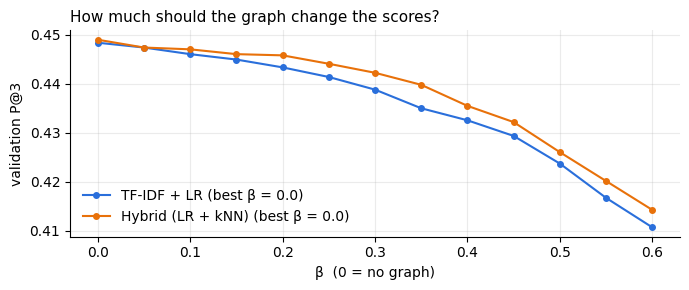

In [16]:
betas = np.round(np.arange(0, 0.61, 0.05), 2)
curves = {name: [at_k(Y_va, graph_rerank(Sv, b_), 3)[0] for b_ in betas]
          for name, Sv in {"TF-IDF + LR": S_va_lr, "Hybrid (LR + kNN)": S_va_hyb}.items()}
BETA = {name: float(betas[int(np.argmax(c))]) for name, c in curves.items()}

fig, ax = plt.subplots(figsize=(7, 3))
for (name, c), col in zip(curves.items(), [BLUE, ORANGE]):
    ax.plot(betas, c, "-o", ms=4, color=col, label=f"{name} (best β = {BETA[name]})")
ax.set_xlabel("β  (0 = no graph)"); ax.set_ylabel("validation P@3")
ax.set_title("How much should the graph change the scores?", loc="left", fontsize=11)
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

**How to read the curve:** the height at β = 0 is the model **without** the graph. If the curve rises before falling, the graph helps; the peak = the best amount of graph. If it only falls, the graph adds nothing on top of that model.

### 📊 Result: tuning β: the graph does not help as a "booster"
- **Best β = 0 for both models** (LR 0.448, Hybrid 0.449); validation P@3 only **falls** as β grows (→ ~0.41 at β = 0.6).
- **Why:**
  1. **Which attribute, not which value:** the graph says "human hair ⇒ some Hair Type", but straight / wavy / curly are **alternatives** → boosting the most common (straight) **overrides correct text evidence**.
  2. **LR already knows it:** the same words that predict *human hair* also predict its partners → the graph repeats LR (same lesson as kNN in Phase 3).
  3. **Wrong anchors spread errors** to their partners.
- **Better uses of the graph:** a **conflict filter** (push down tags that never co-occur with the confident ones; boost nothing) and **attribute-level completion** ("this product should have a Hair Type"; the **text** picks which) → the agent's job (Phase 6).
- With β = 0 the ablation shows no difference → rerun it with a small fixed β (e.g. 0.1) to see *where* the graph pushes.

In [18]:
S_va_lrg, S_te_lrg = graph_rerank(S_va_lr, BETA["TF-IDF + LR"]), graph_rerank(S_te_lr, BETA["TF-IDF + LR"])
S_va_hg,  S_te_hg  = graph_rerank(S_va_hyb, BETA["Hybrid (LR + kNN)"]), graph_rerank(S_te_hyb, BETA["Hybrid (LR + kNN)"])
results["TF-IDF + LR + graph"] = evaluate(Y_te, S_te_lrg, tune_threshold(Y_va, S_va_lrg))
results["Hybrid + graph"]      = evaluate(Y_te, S_te_hg,  tune_threshold(Y_va, S_va_hg))
pd.DataFrame(results).T[["micro-F1", "macro-F1", "P@3", "R@3", "MAP"]].round(3)

,micro-F1,macro-F1,P@3,R@3,MAP
Popularity,0.152,0.007,0.134,0.147,0.198
TF-IDF + LR,0.579,0.306,0.463,0.655,0.683
DistilBERT,0.589,0.318,0.463,0.651,0.686
kNN (embeddings),0.526,0.266,0.418,0.584,0.613
kNN (TF-IDF),0.541,0.269,0.430,0.603,0.634
Hybrid (LR + kNN),0.580,0.304,0.465,0.659,0.687
TF-IDF + LR + graph,0.579,0.306,0.463,0.655,0.683
Hybrid + graph,0.580,0.304,0.465,0.659,0.687


### 📊 Result: test scores with the tuned β
**What the cell does:** applies each model's **best β from validation** to the **test** scores and adds two rows: *TF-IDF + LR + graph* and *Hybrid + graph*.

**Result:** the "+ graph" rows are **identical** to the rows without graph (LR: P@3 0.463, micro-F1 0.579, macro-F1 0.306 · Hybrid: P@3 0.465, micro-F1 0.580, macro-F1 0.304).

**Why identical?** Validation chose **β = 0** for both models, and with β = 0:
new score = (1 − 0) × old score + 0 × support = **old score** → "+ graph" = **no graph**.
Not a bug: validation said boosting partners only **hurts** (graph says *which attribute*, not *which value*; LR already knows the partners; wrong anchors spread errors).

**Next experiments:**
1. **Conflict filter:** use the graph only to **push down impossible tags** (never seen with the top tag), never to boost → does val P@3 rise?
2. **Ablation with a small fixed β (0.1):** see **where** the graph pushes (rare / implicit tags), even if overall P@3 drops slightly.

## 7 · Ablation: what exactly does the graph change? 📊
**Ablation** = remove one component and measure the difference. Here: the **same model with vs without** the graph. One overall number can hide where it helps, so we look at three views:
1. **Overall** (with − without)
2. **Rare vs common** tags
3. **Explicit vs implicit** tags — the graph should help most where the text is silent

In [19]:
pairs_ = {"TF-IDF + LR": (S_te_lr, S_te_lrg, S_va_lr, S_va_lrg), "Hybrid": (S_te_hyb, S_te_hg, S_va_hyb, S_va_hg)}
rows = []
for name, (S0, S1, V0, V1) in pairs_.items():
    e0, e1 = evaluate(Y_te, S0, tune_threshold(Y_va, V0)), evaluate(Y_te, S1, tune_threshold(Y_va, V1))
    rows.append({"model": name, **{m: e1[m] - e0[m] for m in ["micro-F1", "macro-F1", "P@3", "R@3", "MAP"]}})
print("Difference = with graph − without graph (positive = the graph helps)")
pd.DataFrame(rows).set_index("model").round(3)

Difference = with graph − without graph (positive = the graph helps)


,micro-F1,macro-F1,P@3,R@3,MAP
model,,,,,
TF-IDF + LR,0.0,0.0,0.0,0.0,0.0
Hybrid,0.0,0.0,0.0,0.0,0.0


### 🛡️ Conflict filter: push down tags that don't fit (never boost)
**Goal:** a safer use of the graph than boosting: only **shrink** tags that **never** appeared with the product's top tag.

**Example: hair bundle**: scores: human hair **0.90** (top tag) · wavy 0.22 · cream 0.25
1. Top tag = `human hair`
2. For every other tag: *ever seen together with human hair in train?*
   - `wavy` → yes (513×) → **keep** 0.22
   - `cream` → never → **shrink**: 0.25 × γ
3. **γ = how hard to shrink:** γ = 1 → no filter · γ = 0.3 → cream = 0.075 → drops out of the top-3

In [21]:
def conflict_filter(S, gamma, n_anchor=1):
    # push down tags that (almost) never appear with the top tag(s); boost nothing
    top = np.argsort(-S, axis=1)[:, :n_anchor]
    ok = np.zeros_like(S, dtype=bool)
    for k in range(n_anchor):
        ok |= (Cmat[top[:, k]] > 0)                     # tag seen at least once with this anchor
    ok[np.arange(len(S))[:, None], top] = True           # keep the anchors themselves
    return np.where(ok, S, S * gamma)                    # gamma < 1 shrinks incompatible tags

for g in [1.0, 0.7, 0.5, 0.3, 0.1]:
    print(f"gamma {g}: val P@3 = {at_k(Y_va, conflict_filter(S_va_lr, g), 3)[0]:.4f}")

gamma 1.0: val P@3 = 0.4483
gamma 0.7: val P@3 = 0.4487
gamma 0.5: val P@3 = 0.4481
gamma 0.3: val P@3 = 0.4473
gamma 0.1: val P@3 = 0.4475


**Result (val P@3):** γ 1.0 → 0.4483 · 0.7 → 0.4487 · 0.5 → 0.4481 · 0.3 → 0.4473 · 0.1 → 0.4475 → **no effect** (±0.001)
- LR **rarely** puts impossible tags (cream on hair) in its top-3 → shrinking them changes nothing
- when the **top tag is wrong**, the filter shrinks **correct** tags → gains and losses cancel

In [22]:

# Ablation: several graph variants on top of TF-IDF + LR, three views at once
def contains(value, text):
    return re.search(r"(?<!\w)" + re.escape(value) + r"(?!\w)", text) is not None

low = te_df["clean"].str.lower().values
tp = pd.DataFrame([(i, j, contains(TAG_VAL[j], low[i])) for i in range(len(te_df)) for j in np.flatnonzero(Y_te[i])],
                  columns=["row", "tag", "explicit"])
present = np.flatnonzero(Y_te.sum(0) > 0)
rare = present[Y_tr.sum(0)[present] < 50]

def views(S_te, S_va):
    thr = tune_threshold(Y_va, S_va)
    e = evaluate(Y_te, S_te, thr)
    f1 = f1_score(Y_te, binarize(S_te, thr), average=None, labels=rare, zero_division=0)
    top5 = np.argsort(-S_te, axis=1)[:, :5]
    hit = np.array([j in top5[i] for i, j in zip(tp["row"], tp["tag"])])
    return {"P@3": e["P@3"], "macro-F1": e["macro-F1"], "rare-tag F1 (<50)": f1.mean(),
            "explicit found (top-5)": hit[tp["explicit"].values].mean(),
            "implicit found (top-5)": hit[~tp["explicit"].values].mean()}

variants = {"no graph (β = 0)": (S_te_lr, S_va_lr)}
for b_ in [0.1, 0.2, 0.3]:
    variants[f"boost β = {b_}"] = (graph_rerank(S_te_lr, b_), graph_rerank(S_va_lr, b_))
if "conflict_filter" in globals():
    variants["conflict filter (γ = 0.3)"] = (conflict_filter(S_te_lr, 0.3), conflict_filter(S_va_lr, 0.3))

abl = pd.DataFrame({name: views(*S) for name, S in variants.items()}).T
print("Each row = TF-IDF + LR with a different use of the graph (test set)")
display(abl.round(3))
print("\nDifference vs no graph (positive = the graph helps):")
(abl - abl.iloc[0]).iloc[1:].round(3)

Each row = TF-IDF + LR with a different use of the graph (test set)


,P@3,macro-F1,rare-tag F1 (<50),explicit found (top-5),implicit found (top-5)
no graph (β = 0),0.463,0.306,0.162,0.852,0.640
boost β = 0.1,0.462,0.296,0.153,0.846,0.640
boost β = 0.2,0.459,0.287,0.144,0.838,0.636
boost β = 0.3,0.455,0.276,0.135,0.821,0.630
conflict filter (γ = 0.3),0.463,0.306,0.163,0.847,0.641



Difference vs no graph (positive = the graph helps):


,P@3,macro-F1,rare-tag F1 (<50),explicit found (top-5),implicit found (top-5)
boost β = 0.1,-0.001,-0.009,-0.009,-0.006,0.000
boost β = 0.2,-0.004,-0.019,-0.018,-0.013,-0.004
boost β = 0.3,-0.009,-0.030,-0.027,-0.030,-0.010
conflict filter (γ = 0.3),-0.000,0.001,0.001,-0.004,0.001


### 📊 Result: ablation: different uses of the graph on TF-IDF + LR (test set)
**Difference vs no graph** (positive = the graph helps):

| Variant | P@3 | macro-F1 | rare F1 (<50) | explicit | implicit |
|---|---|---|---|---|---|
| boost β = 0.1 | −0.001 | −0.009 | −0.009 | −0.006 | 0.000 |
| boost β = 0.2 | −0.004 | −0.019 | −0.018 | −0.013 | −0.004 |
| boost β = 0.3 | −0.009 | −0.030 | −0.027 | −0.030 | −0.010 |
| conflict filter γ = 0.3 | 0.000 | +0.001 | +0.001 | −0.004 | +0.001 |

1. **Boosting hurts everywhere**, more β → more damage; **rare tags hurt most** (−0.027).
2. **Even implicit tags don't improve** (0.640 → 0.630), the graph's best hope.
3. **Conflict filter ≈ 0** in every view.

**Why the graph adds nothing as a score correction:**
- **LR already knows the co-occurrences**: the same words predict a tag and its partners → scores already consistent with the graph.
- **Boosting favours common partners** (straight over curly) → **rare tags lose**.
- **The graph is built from incomplete labels** → P(partner | tag) is underestimated.

**For the proposal:** the graph's value is **not** score correction but **explanation** (communities, partners), **completeness checks** ("human hair ⇒ some Hair Type suggested?") and **conflict detection** for the verifier. The remaining gap (implicit tags 64%) needs **world knowledge** → **Phase 5: LLMs**.

## 8 · Tag embeddings with random walks (the node2vec idea) 📘

### The problem PMI can't see
PMI only measures **direct** links: "do these two tags appear **together**?"
But some tags are **alternatives**: they never appear together, yet play the **same role**:
- `Hair Type=wavy` and `Hair Type=curly` → a product is usually wavy **or** curly, rarely both → **low PMI**
- but both appear with the **same partners**: human hair, natural, weave, sew-in…

→ PMI says "unrelated", although they are clearly **the same kind of tag**.

### The idea
**Give every tag a vector (an embedding)**, so that tags with **similar partners** get **similar vectors**, even if they never appear together. Just like MiniLM gives similar **texts** similar vectors, here we do it for **tags**.

The idea comes from language: *"you know a word by the company it keeps."* Words like *cat* and *dog* rarely appear in the same spot of a sentence, but they appear **near the same words** (pet, food, cute), so they get similar vectors.

### How (DeepWalk / node2vec, simplified): 3 steps
**Step 1: random walks = make "sentences" from the graph**
Start at a tag and hop to a neighbour, again and again (stronger edges are more likely to be chosen):
> human hair → straight → natural → human hair → wavy → weave → human hair → curly …

**Step 2: treat each walk as a sentence**, and each tag as a word.

**Step 3: train Word2Vec** on these "sentences" (20 walks per tag, 12 steps each). Tags that show up **in similar places of the walks** (with the same neighbours) get **similar vectors**.

### What we get
- One **32-number vector per tag**
- `most_similar(tag)` → tags with a **similar role**, e.g. for *wavy*: curly, straight, kinky (the other hair types), even though they're rarely on the same product

### Why it could be useful
- **Rare tags borrow strength** from tags with similar roles (e.g. a rare hair type sits close to common ones)
- An alternative to P(b|a) for re-ranking or for the agent's "related tags" tool (exercise)
- It is the **input** that a GCN (Section 9) would start from

*Forecasting analogy:* learning an embedding for each weather station from **which stations it behaves like**, so two stations that are never directly compared still end up close because they react to the same neighbours.

In [26]:
def random_walks(G, n_walks=20, length=12, seed=0):
    rng = np.random.default_rng(seed)
    nodes = [n for n in G.nodes if G.degree(n) > 0]
    walks = []
    for _ in range(n_walks):
        for start in rng.permutation(nodes):
            walk = [start]
            for _ in range(length - 1):
                nb = list(G.neighbors(walk[-1]))
                w = np.array([G[walk[-1]][x]["weight"] for x in nb])
                walk.append(nb[rng.choice(len(nb), p=w / w.sum())])
            walks.append(walk)
    return walks

walks = random_walks(G)
print(f"{len(walks):,} walks · example:\n  " + " → ".join(t.split('=', 1)[1] for t in walks[0]))

4,060 walks · example:
  cotton → mink fur → pair → faux mink → mink fur → individual → polyester → individual → faux mink → cruelty free → non-toxic → long-lasting


In [27]:
from gensim.models import Word2Vec

w2v = Word2Vec(walks, vector_size=32, window=4, min_count=1, sg=1, workers=2, epochs=10, seed=42)
probe = top_tag
print(f"Tags most similar to {probe} (by tag embedding):")
pd.DataFrame(w2v.wv.most_similar(probe, topn=10), columns=["tag", "cosine"]).round(3)

Tags most similar to Material=human hair (by tag embedding):


,tag,cosine
0,Installation Type=weave,0.956
1,Color=natural,0.954
2,Installation Type=fusion,0.952
3,Installation Type=clip-in,0.941
4,Special Feature=tangle free,0.939
5,Installation Type=tape,0.935
6,Installation Type=tape-in,0.930
7,Hair Type=straight,0.924
8,Installation Type=sew-in,0.922
9,Hair Type=kinky,0.904


**How to read it:** the closest tags in embedding space. Compare with `show_ego(top_tag)` from Section 5: do you see tags that are **similar in role** but rarely appear **together** (e.g. two alternative hair types)? That is what embeddings add beyond PMI. (Using them for re-ranking is an exercise.)

### 🚶 What these two cells did, and what we learned

#### Cell 1: random walks = make "sentences" from the graph
**Why:** Word2Vec learns from **sentences**, but a graph has none → we **walk** around the graph and write down every tag we visit.

**Picture a city map:** tag = a place · edge = a road · edge weight (NPMI) = road size.
Start somewhere, walk **12 steps**; at each crossing pick a road **at random**, but **bigger roads are more likely**.

*Tiny example:* from `human hair` there are 3 roads: straight (0.5), wavy (0.4), natural (0.1)
→ chance to go to straight **50%**, wavy **40%**, natural **10%** → roll the dice → repeat from the new place.

**In the code:** every tag starts a walk (`for start in …`) → look at its roads (`G.neighbors`) → turn road sizes into probabilities (`p = w / w.sum()`) → roll the dice (`rng.choice`) → 12 steps → repeat **20 times** per tag.

**Result:** **4,060 walks** = 20 × 203 tags (the 8 isolated tags have no roads). Example:
> cotton → mink fur → pair → faux mink → mink fur → individual → polyester → individual → faux mink → cruelty free → non-toxic → long-lasting

→ all **false-eyelash tags**: the walk **stays inside one product family**, because the roads there connect to each other.

#### Cell 2: Word2Vec = one vector per tag
**Idea:** *"you know a word by the company it keeps"* → tags that appear in the **same walks** get **similar vectors**.
Settings: 32 numbers per tag · tags within 4 steps count as neighbours · skip-gram · 10 passes over the walks.

**Result: the 10 tags closest to `Material=human hair`** (cosine 0.90–0.96): weave, natural colour, fusion, clip-in, tangle free, tape, tape-in, straight, sew-in, kinky.
1. **All are hair-extension tags** → the embedding learned the **hair-extension family**.
2. **It found the alternatives PMI misses:** the Installation Types (weave, fusion, clip-in, tape, sew-in) rarely appear **together** (low PMI), but sit **close** here because they share the **same partners** → **"similar role"**.
3. **vs `show_ego`:** direct partners = the most **frequent** (straight, natural, wavy); the embedding also brings **rarer** tags of the same family (fusion, tape, tangle free) → helpful for the **long tail**.
4. **Watch-outs:** cosines are all very high → mostly says *"same family"*, not fine-grained (small graph of 211 tags); `tape` vs `tape-in` = likely the **same value written twice** → add to `TAG_MERGE`.

**Why it matters for the agent:** a "related tags" tool can use these vectors to suggest **alternatives** ("wavy? or maybe curly / kinky?") and help **rare tags** borrow strength from their family. A GCN (Section 9) would start from vectors like these.

## 9 · GCN: the deep-learning version (concept, optional) 📘
Our re-ranking uses a **fixed** rule (P(b|a) from counts). A **Graph Convolutional Network (GCN)** *learns* how to use the graph.

**ML-GCN idea (Chen et al., 2019):**
1. Each **tag** starts with a vector (e.g. its node2vec embedding or the text embedding of its name)
2. A GCN **mixes each tag's vector with its graph neighbours'** (2 layers) → each tag becomes one **classifier vector**
3. Score of tag b for a product = **text embedding · classifier vector of b**
4. Everything is trained end-to-end with BCE, like DistilBERT in Phase 2

→ Rare tags **borrow strength** from their frequent neighbours in the graph — exactly the long-tail problem.

**Why we don't build it here:** it needs PyTorch Geometric and careful tuning; the simple re-ranking already tells us **whether the graph contains useful information**. If Section 7 shows a clear gain, a GCN is a strong candidate for Phase 7 experiments.

## 10 · Scoreboard after Phase 4
Gray = popularity · blue = Phase 2 · orange = Phase 3 · green = Phase 4 (graph)

,micro-F1,macro-F1,P@3,R@3,MAP
Popularity,0.152,0.007,0.134,0.147,0.198
TF-IDF + LR,0.579,0.306,0.463,0.655,0.683
DistilBERT,0.589,0.318,0.463,0.651,0.686
kNN (embeddings),0.526,0.266,0.418,0.584,0.613
kNN (TF-IDF),0.541,0.269,0.430,0.603,0.634
Hybrid (LR + kNN),0.580,0.304,0.465,0.659,0.687
TF-IDF + LR + graph,0.579,0.306,0.463,0.655,0.683
Hybrid + graph,0.580,0.304,0.465,0.659,0.687


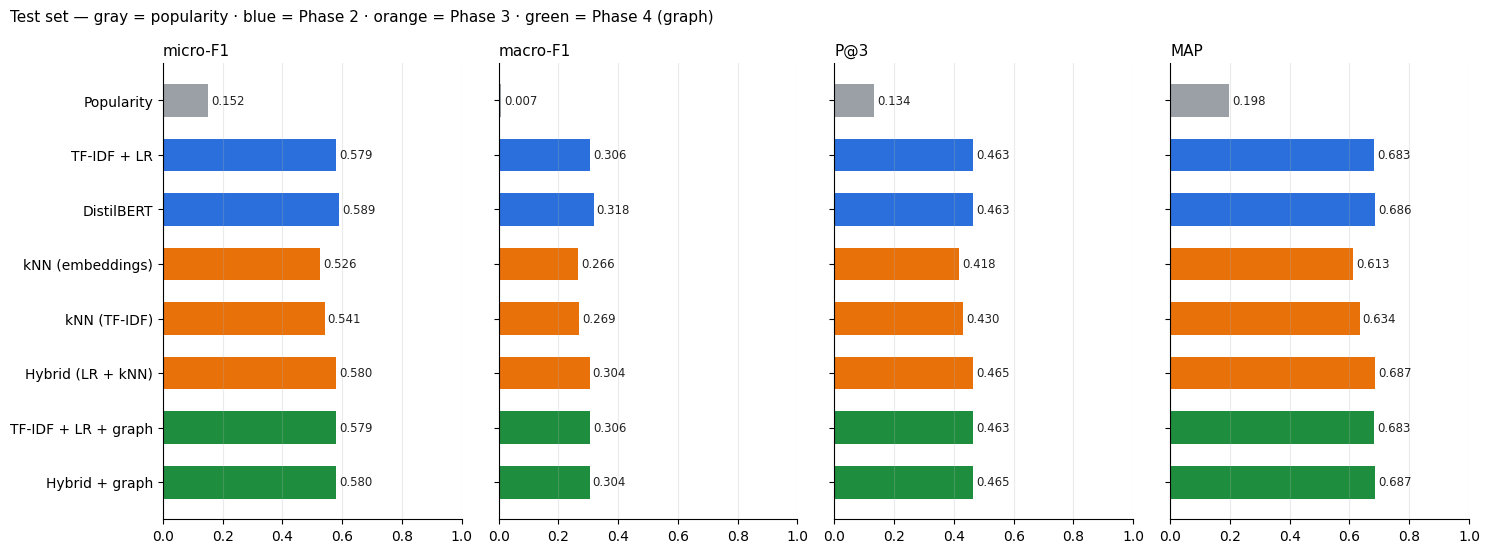

In [28]:
res = pd.DataFrame(results).T
display(res[["micro-F1", "macro-F1", "P@3", "R@3", "MAP"]].round(3))

PH3 = {"kNN (embeddings)", "kNN (TF-IDF)", "Hybrid (LR + kNN)"}
PH4 = {"TF-IDF + LR + graph", "Hybrid + graph"}
colors = [GRAY if n == "Popularity" else GREEN if n in PH4 else ORANGE if n in PH3 else BLUE for n in res.index]
show = ["micro-F1", "macro-F1", "P@3", "MAP"]
fig, axes = plt.subplots(1, len(show), figsize=(15, 0.55 * len(res) + 1.2), sharey=True)
for ax, m in zip(axes, show):
    bars = ax.barh(res.index, res[m], color=colors, height=0.6)
    for b_, v in zip(bars, res[m]):
        ax.text(v + 0.01, b_.get_y() + b_.get_height() / 2, f"{v:.3f}", va="center", fontsize=8.5, color=INK)
    ax.set_title(m, loc="left", fontsize=11); ax.set_xlim(0, 1)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", alpha=0.25)
axes[0].invert_yaxis()
fig.suptitle("Test set — gray = popularity · blue = Phase 2 · orange = Phase 3 · green = Phase 4 (graph)", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); plt.show()

### 📊 Scoreboard after Phase 4
**The green rows are copies:** "TF-IDF + LR + graph" = "TF-IDF + LR" and "Hybrid + graph" = "Hybrid", because validation chose **β = 0** (graph boosting only hurt) → remove or rename them.

**The ceiling is unchanged: P@3 ≈ 0.46**
- 🥇 **tied top:** Hybrid 0.465 · TF-IDF + LR 0.463 · DistilBERT 0.463 (macro-F1 0.30–0.32)
- 🥈 **retrieval alone:** kNN TF-IDF 0.430 · kNN MiniLM 0.418 (macro-F1 0.27)
- **floor:** Popularity 0.134

**What Phases 2–4 showed together:**
| Phase | Extra information tried | Result |
|---|---|---|
| 2 | deeper text model (DistilBERT) | = TF-IDF + LR, at ~20× the cost |
| 3 | tags of **similar products** (kNN) | no overall gain; rare tags +11% |
| 4 | **relations between tags** (graph) | no gain as score correction; useful for explanation, completeness and conflict checks |

→ All three are **derived from the same vendor data** (short titles + incomplete tags), so they mostly **repeat** what TF-IDF + LR already learned.
→ The next step needs **knowledge from outside this dataset**: an **LLM's world knowledge** (Phase 5).

## 11 · Save for Phases 5–6
The graph becomes a **tool** for the agent: "which tags usually come with X?" and "is tag Y compatible with tag Z?".

In [29]:
np.save(f"{OUT}/cooccurrence_train.npy", Cmat)
np.savez_compressed(f"{OUT}/tag_graph_matrices.npz", PMI=PMI.astype("float32"), NPMI=NPMI.astype("float32"),
                    COND=COND.astype("float32"), reliable=reliable)
nx.write_graphml(G, f"{OUT}/tag_graph.graphml")
np.save(f"{OUT}/scores_test_lr_graph.npy", S_te_lrg.astype("float32"))
np.save(f"{OUT}/scores_test_hybrid_graph.npy", S_te_hg.astype("float32"))
json.dump({"results_test": {m: {k: round(float(v), 4) for k, v in r.items()} for m, r in results.items()},
           "settings": {"MIN_CO": MIN_CO, "n_anchor": 3, "beta": BETA}},
          open(f"{OUT}/results.json", "w"), indent=2)
print("Saved:", sorted(os.listdir(OUT)))

Saved: ['cooccurrence_train.npy', 'results.json', 'scores_test_hybrid_graph.npy', 'scores_test_lr_graph.npy', 'tag_graph.graphml', 'tag_graph_matrices.npz']


## 12 · Phase 4 Summary 🎓

### 🧩 What we built
| Piece | What it is | Our numbers |
|---|---|---|
| **Co-occurrence matrix** | C = Yᵀ·Y on **train**: how many products share each pair of tags | 211 × 211 |
| **PMI / NPMI / P(b\|a)** | "together more than chance?" · normalized (−1…+1) · "if a, how often b?" | pairs with ≥ 5 co-occurrences |
| **Tag graph** | nodes = tags, edges = NPMI > 0 and ≥ 5 co-occurrences | **211 tags · 1,038 edges · 8 isolated · 6 communities** |
| **Graph re-ranking (boost)** | new = (1 − β)·score + β·support from the top-3 anchor tags | best **β = 0** (LR and Hybrid) |
| **Conflict filter** | shrink tags never seen with the top tag (×γ), boost nothing | best γ = 0.7 → val P@3 0.4487 vs 0.4483 |
| **Tag embeddings** | random walks (4,060) + Word2Vec → 32 numbers per tag | hair tags cluster at cosine 0.90–0.96 |

### 🔑 Key findings
**What the graph knows** ✅
1. **6 product families discovered from tags alone** (no titles read): 💄 makeup · 🧴 skin & body care · 💅 nails · 💇 hair extensions · 👁️ lashes & accessories · 🧖 hair care.
2. **Clear product logic:** of `human hair` products, straight **43%** · wavy **34%** · curly **19%** · kinky **4%** → almost always *some* Hair Type. `weave` is rare (P 0.11) but tightly linked (NPMI 0.45).
3. **Conflicts:** ___ tag pairs from different attributes are expected ≥ 10× by chance but seen ≤ 1× → rules for the verifier.
4. **Tag embeddings find alternatives** PMI misses: Installation Types (weave, fusion, clip-in, tape, sew-in) rarely co-occur but sit close together; rarer family members (fusion, tape, tangle free) surface too.

**What the graph does *not* do** ❌
5. **Boosting partners hurts:** best β = 0; at β = 0.3: P@3 −0.009 · macro-F1 −0.030 · **rare-tag F1 −0.027** · implicit −0.010.
6. **Conflict filter ≈ no effect** (±0.001): LR rarely puts impossible tags in its top-3 anyway.
7. **Implicit tags not improved** (0.640 → 0.630–0.641): the graph adds no information the text model lacks.

**Why**
- The graph says **which attribute**, not **which value**: straight / wavy / curly are **alternatives**, and boosting the most common one overrides correct text evidence.
- **LR already learned the co-occurrences:** the same words predict a tag and its partners.
- **Built from incomplete labels** → P(partner | tag) is underestimated.

### 🏁 Scoreboard after Phases 2–4 (test set)
| Model | micro-F1 | macro-F1 | P@3 | MAP |
|---|---|---|---|---|
| Popularity | 0.152 | 0.007 | 0.134 | 0.198 |
| TF-IDF + LR | 0.579 | 0.306 | 0.463 | 0.683 |
| DistilBERT | **0.589** | **0.318** | 0.463 | 0.686 |
| kNN (TF-IDF) | 0.541 | 0.269 | 0.430 | 0.634 |
| Hybrid (LR + kNN) | 0.580 | 0.304 | **0.465** | **0.687** |
| + graph (β = 0) | = same as without graph | | | |

**Ceiling unchanged at P@3 ≈ 0.46.** Deeper text model (Phase 2), similar products (Phase 3) and tag relations (Phase 4) all come from the **same vendor data** → they mostly **repeat** what TF-IDF + LR already knows.

### 📝 Paper sentence
*"A tag co-occurrence graph recovers the catalogue's product families without reading any text, but using it to re-rank model scores does not improve tagging (best interpolation weight β = 0); co-occurrence information appears to be already captured by the text classifier, and the graph indicates which attribute a product should have rather than which value."*

### 🧪 Exercises (pick 2+)
1. **Attribute-level completion:** if the graph says "human hair ⇒ Hair Type" but no Hair Type is in the top-5, add the **best-scoring Hair Type from the text model** → does recall rise?
2. Use **NPMI** or **tag-embedding similarity** instead of P(b|a) in `graph_rerank`.
3. Tune β on **macro-F1** instead of P@3 → does the graph help the long tail when that is the target?
4. Merge `tape` / `tape-in` (and similar) in `TAG_MERGE`, rerun Phases 2–4.

### 🧰 What we keep for the agent (Phase 6)
- **Explanation tool:** "tags that usually come with X" (`show_ego`)
- **Completeness check:** "a human-hair product should have *some* Hair Type; is one suggested?"
- **Conflict check:** "tag Y never appears with tag X → reject or flag"
- **Related-tags tool:** alternatives from tag embeddings ("wavy? or curly / kinky?")

### ➡️ Next: Phase 5 (LLMs)
All our signals so far come from **this dataset**. An LLM brings **world knowledge** from outside it ("a body butter is moisturizing", "a bonnet is not a cream", "Aqua Bounce is a gel") and can combine **text + similar products + graph hints** in one prompt (RAG).

**Notion tasks completed:** graph basics, PMI, node2vec · tag co-occurrence graph · graph re-ranking / tag completion 🎯 · ablation with vs without graph